# MEI003 Biomedical Data and Machine Learning - 2025/1 | DL_LAB_2025 - FANI TZINA & GEORGE PAPADOPOYLOS

Use the medmnist - pneumonia dataset (28x28 iage size) we explored in the DL lesson.

Create a CNN-based model with keras for the binary classification problem (having as a starting point the simple models discussed during the lesson).

Calculate performance metrics on test set.

Test some <batchsize, epoch> pairs. Which one is the best?

Does the change in 'loss' function or 'metric' (other accuracy) have an effect in the performance?

If you remove the CNN layer with the highest dimension,  would that have an effect?

Does it play a role if relu or leakyrelu activation is used?

Make a report to explain the architextures and test performed, along with the results in each case. Discuss your findings.

In [1]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.7 MB/s eta 0:00:00


In [2]:
import medmnist
from medmnist import INFO
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
import os, random, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
# 1--choose dataset here (each group can change this string)
DATASET_NAME = "pneumoniamnist"  # or "pathmnist", "bloodmnist"

# 2-- look up dataset metadata and corresponding class
info = INFO[DATASET_NAME]
DataClass = getattr(medmnist, info["python_class"])

# MAIN

In [4]:
# 3--create train / val / test splits (download happens automatically on first run)
train_dataset = DataClass(split="train", download=True)
#val_dataset   = DataClass(split="val",   download=True)
test_dataset  = DataClass(split="test",  download=True)

100%|██████████| 4.17M/4.17M [00:00<00:00, 4.56MB/s]


In [5]:
# 4--get images and labels as NumPy arrays
x_train, y_train = train_dataset.imgs, train_dataset.labels
#x_val,   y_val   = val_dataset.imgs,   val_dataset.labels
x_test,  y_test  = test_dataset.imgs,  test_dataset.labels

In [6]:
print("Raw shapes:")
print("x_train:", x_train.shape, "y_train:", y_train.shape)
#print("x_val:  ", x_val.shape,   "y_val:  ", y_val.shape)
print("x_test: ", x_test.shape,  "y_test: ", y_test.shape)

Raw shapes:
x_train: (4708, 28, 28) y_train: (4708, 1)
x_test:  (624, 28, 28) y_test:  (624, 1)


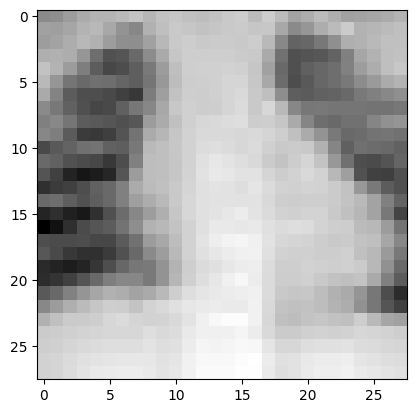

[1]


In [7]:
sample = 250
image = x_train[sample]
fig = plt.figure
plt.imshow(image, cmap='gray')
plt.show()
print(y_train[sample])

In [8]:
# 5--basic preprocessing
# Convert to float32 and normalize to [0, 1]
x_train = x_train.astype("float32") / 255.0
#x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

In [9]:
# Datasets have labels of shape (N, 1) - flatten to (N,)
y_train = y_train.squeeze()
#y_val   = y_val.squeeze()
y_test  = y_test.squeeze()

# One-hot encode the labels
num_classes = len(np.unique(y_train))  # len([0, 1]) ---> 2

## Converts integer labels into vectors where: The correct class index is 1 and All other entries are 0
y_train = keras.utils.to_categorical(y_train, num_classes)
#y_val = keras.utils.to_categorical(y_val, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print("\nAfter preprocessing:")
print("x_train:", x_train.shape, "y_train:", y_train.shape, "dtype:", x_train.dtype)
#print("x_val:  ", x_val.shape,   "y_val:  ", y_val.shape)
print("x_test: ", x_test.shape,  "y_test: ", y_test.shape)


After preprocessing:
x_train: (4708, 28, 28) y_train: (4708, 2) dtype: float32
x_test:  (624, 28, 28) y_test:  (624, 2)


**SOS!** The network expects the target labels to be in one-hot form so it can compute **categorical crossentropy loss** correctly.

If you pass integer labels instead of one-hot, the loss function won’t work as intended for **categorical_crossentropy**.

**Note: If you later switch to binary_crossentropy + single output unit with sigmoid, you don’t need one-hot encoding.
You’d keep labels as integers (0 or 1) and use shape (N,).**

(array([[3494.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
         1214.],
        [1214.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
         3494.]]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <a list of 2 BarContainer objects>)

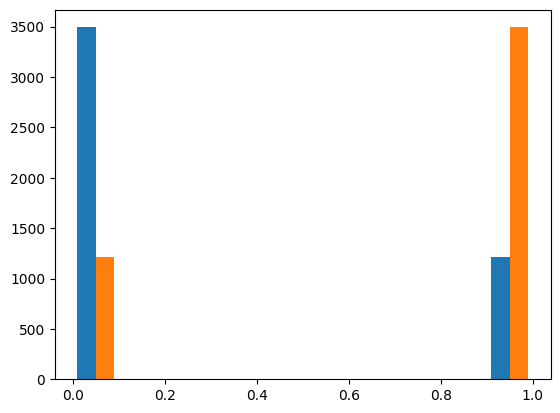

In [10]:
import matplotlib.pyplot as plt
plt.hist(y_train)

In [11]:
from tensorflow import keras
from tensorflow.keras import layers

input_shape=(28,28,1)
num_classes=2

# test-test

In [ ]:
model_A = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(16, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

In [ ]:
batch_size = 20 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_A.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_A.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.1)

In [ ]:
score = model_A.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

y_true=[]
y_pred=[]
ln=10
predictions = model_A.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

super aplo model, xwris batch normal layer, me 15 epoch k batch=16, dropout=0.5---> ACC = 81.89%

# Test some <batchsize, epoch> pairs. Which one is the best?

In [12]:
model = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation='sigmoid'),

    ])
#model.summary()

In [13]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 10 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.8585 - loss: 0.3859 - val_accuracy: 0.7808 - val_loss: 1.0396
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9446 - loss: 0.1480 - val_accuracy: 0.9491 - val_loss: 0.1368
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9601 - loss: 0.1135 - val_accuracy: 0.9547 - val_loss: 0.1318
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9594 - loss: 0.1139 - val_accuracy: 0.9618 - val_loss: 0.1067
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9637 - loss: 0.0883 - val_accuracy: 0.8996 - val_loss: 0.2309
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9692 - loss: 0.0741 - val_accuracy: 0.9590 - val_loss: 0.1172
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9728 - loss: 0.0648 - val_accuracy: 0.9661 - val_loss: 0.1092
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9687 - loss: 0.0514 - val_accuracy: 

In [14]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Test loss: 0.8665342330932617
Test accuracy: 0.8621794581413269
[0.8665342330932617, 0.8621794581413269]
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step
(10, 2)
0.8
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.78      1.00      0.88         7

    accuracy                           0.80        10
   macro avg       0.89      0.67      0.69        10
weighted avg       0.84      0.80      0.76        10



In [15]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9746 - loss: 0.0487 - val_accuracy: 0.9604 - val_loss: 0.1529
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9770 - loss: 0.0417 - val_accuracy: 0.9646 - val_loss: 0.1528
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9703 - loss: 0.0546 - val_accuracy: 0.9378 - val_loss: 0.2477
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9764 - loss: 0.0368 - val_accuracy: 0.8331 - val_loss: 1.0037
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9719 - loss: 0.0386 - val_accuracy: 0.9066 - val_loss: 0.4504
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9737 - loss: 0.0308 - val_accuracy: 0.8699 - val_loss: 0.6646
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9688 - loss: 0.0360 - val_accuracy: 0.9661 - val_loss: 0.1643
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9666 - loss: 0.0169 - val_accuracy: 

In [16]:
batch_size = 20 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

Epoch 1/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9494 - loss: 0.0205 - val_accuracy: 0.9703 - val_loss: 0.1713
Epoch 2/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9578 - loss: 0.0120 - val_accuracy: 0.9420 - val_loss: 0.4006
Epoch 3/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9531 - loss: 0.0280 - val_accuracy: 0.9703 - val_loss: 0.1812
Epoch 4/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9662 - loss: 0.0020 - val_accuracy: 0.9689 - val_loss: 0.2523
Epoch 5/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9528 - loss: 0.0201 - val_accuracy: 0.9632 - val_loss: 0.2413
Epoch 6/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9660 - loss: 0.0134 - val_accuracy: 0.9533 - val_loss: 0.2058
Epoch 7/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9612 - loss: 0.0111 - val_accuracy: 0.9632 - val_loss: 0.2268
Epoch 8/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9519 - loss: 0.0087 - val_accuracy: 

In [17]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Test loss: 2.356132745742798
Test accuracy: 0.8333333134651184
[2.356132745742798, 0.8333333134651184]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step
(10, 2)
0.8
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.78      1.00      0.88         7

    accuracy                           0.80        10
   macro avg       0.89      0.67      0.69        10
weighted avg       0.84      0.80      0.76        10



In [18]:
batch_size = 32 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.9630 - loss: 0.0023 - val_accuracy: 0.9646 - val_loss: 0.4108
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9673 - loss: 0.0063 - val_accuracy: 0.9717 - val_loss: 0.2842
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9605 - loss: 0.0169 - val_accuracy: 0.9463 - val_loss: 0.5045
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9726 - loss: 0.0050 - val_accuracy: 0.9477 - val_loss: 0.3935
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9696 - loss: 0.0045 - val_accuracy: 0.9731 - val_loss: 0.2798
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9719 - loss: 0.0015 - val_accuracy: 0.9731 - val_loss: 0.3288
Epoch 7/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9827 - loss: 7.0971e-04 - val_accuracy: 0.9731 - val_loss: 0.3526
Epoch 8/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9700 - loss: 0.0031 - val_accura

In [19]:
model_2 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='sigmoid'),

    ])
#model.summary()

In [20]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_2.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model_2.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9023 - loss: 0.2332 - val_accuracy: 0.7808 - val_loss: 1.6953
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9563 - loss: 0.1226 - val_accuracy: 0.9222 - val_loss: 0.2201
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9628 - loss: 0.0974 - val_accuracy: 0.9547 - val_loss: 0.1403
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9716 - loss: 0.0791 - val_accuracy: 0.9392 - val_loss: 0.1999
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9689 - loss: 0.0886 - val_accuracy: 0.9675 - val_loss: 0.1007
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9733 - loss: 0.0712 - val_accuracy: 0.9505 - val_loss: 0.1976
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9787 - loss: 0.0657 - val_accuracy: 0.9590 - val_loss: 0.1119
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9758 - loss: 0.0606 - val_accuracy: 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step
(10, 2)
0.8
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.78      1.00      0.88         7

    accuracy                           0.80        10
   macro avg       0.89      0.67      0.69        10
weighted avg       0.84      0.80      0.76        10



In [21]:
batch_size = 20 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_2.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# Confusion Matrix
y_true=[]
y_pred=[]
ln=10
predictions = model_2.predict(x_test[:ln])
print(predictions.shape)
for i in range(ln) :
  i1=int(np.argmax(y_test[i,], axis=0))
  i2=int(np.argmax(predictions[i,], axis=0))
  y_true.append(i1)
  y_pred.append(i2)
  #print(i1, i2)

print(accuracy_score(y_true, y_pred))

confusion_matrix(y_true, y_pred)
print(classification_report(y_true,y_pred))

Epoch 1/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9851 - loss: 0.0331 - val_accuracy: 0.9463 - val_loss: 0.1941
Epoch 2/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9874 - loss: 0.0358 - val_accuracy: 0.9604 - val_loss: 0.1411
Epoch 3/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9932 - loss: 0.0175 - val_accuracy: 0.9618 - val_loss: 0.1638
Epoch 4/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9906 - loss: 0.0216 - val_accuracy: 0.9406 - val_loss: 0.3805
Epoch 5/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9922 - loss: 0.0229 - val_accuracy: 0.9632 - val_loss: 0.1491
Epoch 6/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9932 - loss: 0.0132 - val_accuracy: 0.9632 - val_loss: 0.2067
Epoch 7/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9943 - loss: 0.0173 - val_accuracy: 0.9491 - val_loss: 0.2392
Epoch 8/15
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9882 - loss: 0.0309 - val_accuracy: 0

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step
(10, 2)
0.8
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.78      1.00      0.88         7

    accuracy                           0.80        10
   macro avg       0.89      0.67      0.69        10
weighted avg       0.84      0.80      0.76        10



# RELU or LEAKYRELU

In [28]:
leaky_relu_layer1 = keras.layers.LeakyReLU(negative_slope=0.05)
leaky_relu_layer2 = keras.layers.LeakyReLU(negative_slope=0.25)

model_leaky_relu1 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation=leaky_relu_layer1),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation='sigmoid'),

    ])

In [29]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_leaky_relu1.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_leaky_relu1.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_leaky_relu1.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.8861 - loss: 0.3139 - val_accuracy: 0.7808 - val_loss: 1.5124
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9404 - loss: 0.1503 - val_accuracy: 0.9406 - val_loss: 0.1672
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9453 - loss: 0.1337 - val_accuracy: 0.9618 - val_loss: 0.1217
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9561 - loss: 0.1198 - val_accuracy: 0.9406 - val_loss: 0.1458
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9593 - loss: 0.1181 - val_accuracy: 0.9562 - val_loss: 0.1162
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9600 - loss: 0.1094 - val_accuracy: 0.9349 - val_loss: 0.1953
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9645 - loss: 0.0893 - val_accuracy: 0.8501 - val_loss: 0.3955
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9724 - loss: 0.0803 - val_accuracy: 

In [38]:
model_leaky_relu2 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation=leaky_relu_layer2),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation='sigmoid'),

    ])

In [39]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_leaky_relu2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_leaky_relu2.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_leaky_relu2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8837 - loss: 0.3063 - val_accuracy: 0.7808 - val_loss: 1.5655
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9441 - loss: 0.1453 - val_accuracy: 0.9547 - val_loss: 0.1648
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9536 - loss: 0.1176 - val_accuracy: 0.9052 - val_loss: 0.2362
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9633 - loss: 0.1107 - val_accuracy: 0.8840 - val_loss: 0.2807
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9613 - loss: 0.1048 - val_accuracy: 0.8883 - val_loss: 0.2828
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9705 - loss: 0.0827 - val_accuracy: 0.8416 - val_loss: 0.4517
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9647 - loss: 0.0895 - val_accuracy: 0.9576 - val_loss: 0.1366
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9779 - loss: 0.0647 - val_accuracy: 0

In [40]:
model_leaky_relu2_2 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation=leaky_relu_layer2),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='sigmoid'),

    ])

In [41]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_leaky_relu2_2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_leaky_relu2_2.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_leaky_relu2_2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9028 - loss: 0.2349 - val_accuracy: 0.7808 - val_loss: 0.8276
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9545 - loss: 0.1171 - val_accuracy: 0.9052 - val_loss: 0.2535
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9676 - loss: 0.0976 - val_accuracy: 0.9081 - val_loss: 0.2709
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9743 - loss: 0.0855 - val_accuracy: 0.9194 - val_loss: 0.2136
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9729 - loss: 0.0784 - val_accuracy: 0.9321 - val_loss: 0.1698
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9765 - loss: 0.0556 - val_accuracy: 0.9137 - val_loss: 0.2326
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9800 - loss: 0.0541 - val_accuracy: 0.9264 - val_loss: 0.2164
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9816 - loss: 0.0518 - val_accuracy: 0

In [42]:
model_leaky_relu2_1 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation=leaky_relu_layer2),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='sigmoid'),

    ])

In [43]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_leaky_relu2_1.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_leaky_relu2_1.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_leaky_relu2_1.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.8863 - loss: 0.2753 - val_accuracy: 0.7808 - val_loss: 1.5155
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9536 - loss: 0.1207 - val_accuracy: 0.9264 - val_loss: 0.2179
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9598 - loss: 0.1124 - val_accuracy: 0.9576 - val_loss: 0.1277
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9670 - loss: 0.0883 - val_accuracy: 0.9590 - val_loss: 0.1116
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9749 - loss: 0.0738 - val_accuracy: 0.9477 - val_loss: 0.1222
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9783 - loss: 0.0622 - val_accuracy: 0.9038 - val_loss: 0.3279
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9805 - loss: 0.0671 - val_accuracy: 0.9675 - val_loss: 0.1161
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9813 - loss: 0.0596 - val_accuracy: 

**Why ReLU and LeakyReLU end up similar at their best?**

This is actually expected cause:

1. Your dataset is small

2. Your network is not very deep

3. BatchNorm already stabilizes training

So:

* ReLU + good regularization = strong performance

* LeakyReLU + well-chosen α = similar performance

* **LeakyReLU doesn’t magically beat ReLU — it just reduces risk when training becomes unstable.**

#REDUCED MODEL

In [22]:
model_red = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='sigmoid'),
    ])

In [23]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_red.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_red.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_red.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8673 - loss: 0.3580 - val_accuracy: 0.7808 - val_loss: 0.7803
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9432 - loss: 0.1619 - val_accuracy: 0.9293 - val_loss: 0.1688
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9478 - loss: 0.1320 - val_accuracy: 0.9618 - val_loss: 0.1156
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9523 - loss: 0.1194 - val_accuracy: 0.9632 - val_loss: 0.1009
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9561 - loss: 0.1090 - val_accuracy: 0.8515 - val_loss: 0.3624
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9662 - loss: 0.1050 - val_accuracy: 0.9279 - val_loss: 0.1620
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9599 - loss: 0.1126 - val_accuracy: 0.9547 - val_loss: 0.1299
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9707 - loss: 0.0950 - val_accuracy: 0

In [24]:
batch_size = 32 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_red.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_red.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_red.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9820 - loss: 0.0529 - val_accuracy: 0.9675 - val_loss: 0.1304
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9804 - loss: 0.0542 - val_accuracy: 0.9632 - val_loss: 0.1382
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9842 - loss: 0.0376 - val_accuracy: 0.9547 - val_loss: 0.2542
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9868 - loss: 0.0417 - val_accuracy: 0.8727 - val_loss: 0.5320
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9831 - loss: 0.0403 - val_accuracy: 0.9618 - val_loss: 0.2522
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9845 - loss: 0.0375 - val_accuracy: 0.9618 - val_loss: 0.2126
Epoch 7/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9872 - loss: 0.0284 - val_accuracy: 0.9293 - val_loss: 0.7878
Epoch 8/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9807 - loss: 0.0491 - val_accuracy: 0

In [26]:
model_red2 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='sigmoid'),
    ])

In [27]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_red2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_red2.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model_red2.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.8895 - loss: 0.2630 - val_accuracy: 0.8458 - val_loss: 0.2861
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9554 - loss: 0.1201 - val_accuracy: 0.9491 - val_loss: 0.1150
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9621 - loss: 0.1058 - val_accuracy: 0.9590 - val_loss: 0.1239
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9638 - loss: 0.0992 - val_accuracy: 0.9349 - val_loss: 0.1960
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9663 - loss: 0.0828 - val_accuracy: 0.9448 - val_loss: 0.1455
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9712 - loss: 0.0803 - val_accuracy: 0.9321 - val_loss: 0.1687
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9728 - loss: 0.0694 - val_accuracy: 0.9703 - val_loss: 0.0962
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9756 - loss: 0.0690 - val_accuracy: 0



---



# binary_crossentropy + sigmoid

In [8]:
# 3--create train / val / test splits (download happens automatically on first run)
train_set = DataClass(split="train", download=True)
#val_dataset   = DataClass(split="val",   download=True)
test_set  = DataClass(split="test",  download=True)

In [9]:
# 4--get images and labels as NumPy arrays
x_train, y_train = train_set.imgs, train_set.labels
#x_val,   y_val   = val_dataset.imgs,   val_dataset.labels
x_test,  y_test  = test_set.imgs,  test_set.labels

print("Raw shapes:")
print("x_train:", x_train.shape, "y_train:", y_train.shape)
#print("x_val:  ", x_val.shape,   "y_val:  ", y_val.shape)
print("x_test: ", x_test.shape,  "y_test: ", y_test.shape)

# 5--basic preprocessing
# Convert to float32 and normalize to [0, 1]
x_train = x_train.astype("float32") / 255.0
#x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

Raw shapes:
x_train: (4708, 28, 28) y_train: (4708, 1)
x_test:  (624, 28, 28) y_test:  (624, 1)


In [10]:
# Datasets have labels of shape (N, 1) - flatten to (N,)
y_train = y_train.squeeze()
#y_val   = y_val.squeeze()
y_test  = y_test.squeeze()

print("\nAfter preprocessing:")
print("x_train:", x_train.shape, "y_train:", y_train.shape, "dtype:", x_train.dtype)
#print("x_val:  ", x_val.shape,   "y_val:  ", y_val.shape)
print("x_test: ", x_test.shape,  "y_test: ", y_test.shape)


After preprocessing:
x_train: (4708, 28, 28) y_train: (4708,) dtype: float32
x_test:  (624, 28, 28) y_test:  (624,)


In [11]:
input_shape=(28,28,1)

model4 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),

        layers.Dense(1, activation='sigmoid'),

    ])
#model.summary()

In [17]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model4.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model4.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.9949 - loss: 0.0120 - val_accuracy: 0.8685 - val_loss: 0.8443
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.9974 - loss: 0.0070 - val_accuracy: 0.9717 - val_loss: 0.3003
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9964 - loss: 0.0064 - val_accuracy: 0.9293 - val_loss: 0.5801
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9904 - loss: 0.0342 - val_accuracy: 0.9731 - val_loss: 0.2260
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9938 - loss: 0.0165 - val_accuracy: 0.9745 - val_loss: 0.1955
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9999 - loss: 0.0027 - val_accuracy: 0.9745 - val_loss: 0.2277
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9985 - loss: 0.0035 - val_accuracy: 0.9675 - val_loss: 0.2795
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9968 - loss: 0.0096 - val_ac

In [18]:
score = model4.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Test loss: 2.9301369190216064
Test accuracy: 0.8269230723381042
[2.9301369190216064, 0.8269230723381042]


In [21]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model4.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy", "AUC"])

# h ekpaideysh:
model4.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model4.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print("Test AUC:", score[2])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - AUC: 0.9955 - accuracy: 0.9931 - loss: 0.0353 - val_AUC: 0.9751 - val_accuracy: 0.9703 - val_loss: 0.2974
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - AUC: 0.9994 - accuracy: 0.9963 - loss: 0.0092 - val_AUC: 0.9790 - val_accuracy: 0.9731 - val_loss: 0.2689
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - AUC: 1.0000 - accuracy: 0.9985 - loss: 0.0032 - val_AUC: 0.9721 - val_accuracy: 0.9788 - val_loss: 0.2817
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - AUC: 1.0000 - accuracy: 0.9999 - loss: 8.4024e-04 - val_AUC: 0.9792 - val_accuracy: 0.9675 - val_loss: 0.3802
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - AUC: 1.0000 - accuracy: 0.9997 - loss: 6.3834e-04 - val_AUC: 0.9781 - val_accuracy: 0.9689 - val_loss: 0.3310
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - AUC: 1.0000 - accuracy: 1.0000 - loss: 3.2377e-04 - val_AUC: 0.9762 - val_accuracy: 0.9745 - val_loss: 0.3249
Epoch 7/15
251/251 ━━━

In [14]:
batch_size = 20 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 12 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model4.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model4.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

Epoch 1/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.9896 - loss: 0.0332 - val_accuracy: 0.9547 - val_loss: 0.1429
Epoch 2/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9896 - loss: 0.0260 - val_accuracy: 0.9576 - val_loss: 0.2478
Epoch 3/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9967 - loss: 0.0086 - val_accuracy: 0.9661 - val_loss: 0.3220
Epoch 4/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9923 - loss: 0.0244 - val_accuracy: 0.9547 - val_loss: 0.1688
Epoch 5/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9927 - loss: 0.0205 - val_accuracy: 0.9661 - val_loss: 0.2746
Epoch 6/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9926 - loss: 0.0207 - val_accuracy: 0.9661 - val_loss: 0.1737
Epoch 7/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9935 - loss: 0.0164 - val_accuracy: 0.9675 - val_loss: 0.1581
Epoch 8/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9924 - loss: 0.0145 - val_acc

IndexError: list index out of range

In [15]:
score = model4.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Test loss: 2.0511929988861084
Test accuracy: 0.8205128312110901
[2.0511929988861084, 0.8205128312110901]


In [16]:
batch_size = 20 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 12 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model4.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy", "AUC"])

# h ekpaideysh:
model4.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model4.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print("Test AUC:", score[2])
print(score)

Epoch 1/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - AUC: 0.9990 - accuracy: 0.9916 - loss: 0.0254 - val_AUC: 0.9785 - val_accuracy: 0.9689 - val_loss: 0.1623
Epoch 2/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - AUC: 1.0000 - accuracy: 0.9994 - loss: 0.0029 - val_AUC: 0.9781 - val_accuracy: 0.9689 - val_loss: 0.1978
Epoch 3/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - AUC: 1.0000 - accuracy: 0.9985 - loss: 0.0029 - val_AUC: 0.9808 - val_accuracy: 0.9661 - val_loss: 0.1575
Epoch 4/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - AUC: 0.9983 - accuracy: 0.9902 - loss: 0.0325 - val_AUC: 0.9832 - val_accuracy: 0.9675 - val_loss: 0.1521
Epoch 5/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - AUC: 0.9994 - accuracy: 0.9917 - loss: 0.0264 - val_AUC: 0.9729 - val_accuracy: 0.9576 - val_loss: 0.2170
Epoch 6/12
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - AUC: 1.0000 - accuracy: 0.9979 - loss: 0.0069 - val_AUC: 0.9633 - val_accuracy: 0.9562 - val_loss: 0.3057
Epoch 7/12
201/201 ━━━━━━━━━━━━━━

*********

In [22]:
input_shape=(28,28,1)

model5 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(1, activation='sigmoid'),

    ])
#model.summary()

In [23]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model5.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model5.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model5.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8725 - loss: 0.3239 - val_accuracy: 0.7878 - val_loss: 0.4275
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9475 - loss: 0.1486 - val_accuracy: 0.9180 - val_loss: 0.2186
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9583 - loss: 0.1198 - val_accuracy: 0.8402 - val_loss: 0.3482
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9614 - loss: 0.1059 - val_accuracy: 0.8062 - val_loss: 0.5217
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9654 - loss: 0.0935 - val_accuracy: 0.8727 - val_loss: 0.3296
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9734 - loss: 0.0782 - val_accuracy: 0.9180 - val_loss: 0.2494
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9743 - loss: 0.0707 - val_accuracy: 0.7341 - val_loss: 0.7235
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9712 - loss: 0.0706 - val_acc

In [24]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model5.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy", "AUC"])

# h ekpaideysh:
model5.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

score = model5.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print("Test AUC:", score[2])
print(score)

Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - AUC: 0.9987 - accuracy: 0.9872 - loss: 0.0360 - val_AUC: 0.9551 - val_accuracy: 0.9250 - val_loss: 0.3063
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - AUC: 0.9987 - accuracy: 0.9896 - loss: 0.0288 - val_AUC: 0.9847 - val_accuracy: 0.9661 - val_loss: 0.1341
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - AUC: 0.9987 - accuracy: 0.9887 - loss: 0.0330 - val_AUC: 0.9766 - val_accuracy: 0.9646 - val_loss: 0.1983
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - AUC: 0.9985 - accuracy: 0.9873 - loss: 0.0290 - val_AUC: 0.9882 - val_accuracy: 0.9463 - val_loss: 0.2702
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - AUC: 0.9996 - accuracy: 0.9884 - loss: 0.0235 - val_AUC: 0.9454 - val_accuracy: 0.9448 - val_loss: 0.3557
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - AUC: 0.9990 - accuracy: 0.9937 - loss: 0.0183 - val_AUC: 0.9727 - val_accuracy: 0.9689 - val_loss: 0.1683
Epoch 7/15
251/251 ━━━━━━━━━━━━━━

# REDUCED MODEL - BINARY CROSS

In [ ]:
model_reduced = keras.Sequential([
    keras.Input(shape=(28,28,1)),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid'),
])

In [ ]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_reduced.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_reduced.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

In [ ]:
score = model_reduced.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

# LEAKY RELU TEST - BINARY CROSS

In [ ]:
leaky_relu_layer1 = keras.layers.LeakyReLU(negative_slope=0.05)
leaky_relu_layer2 = keras.layers.LeakyReLU(negative_slope=0.25)

model_leaky1 = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding='same', activation=leaky_relu_layer1),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),

        layers.Dense(1, activation='sigmoid'),

    ])

In [ ]:
batch_size = 16 # se kathe kyklo posa deigmata tha xrisimopooihsei
epoch  = 15 # posa rounds tha kanei

# orise tis teleftaies parametrous gia tin ekpaideysi
model_leaky1.compile(loss='binary_crossentropy', optimizer="adam", metrics=["accuracy"])

# h ekpaideysh:
model_leaky1.fit(x_train, y_train, batch_size=batch_size, epochs=epoch, validation_split=0.15)

In [ ]:
# leaky 2
score = model_leaky.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)

In [ ]:
# leaky 1
score = model_leaky1.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])
print(score)